In [1]:
import pandas as pd
import numpy as np
import random
import time
import pickle
import os
import sys

sys.path.append(os.path.abspath('..'))

from sklearn.model_selection import StratifiedKFold
from IPython.display import display

from utils.graphs import plot_confusion_matrix
from utils.util import evaluate_predictions, cross_evaluate
from utils.models import available_models_base, get_model


print("Pandas version: {}".format(pd.__version__))
print("NumPy version: {}".format(np.__version__))

seed = 42
np.random.seed(seed)
random.seed(seed)

Pandas version: 2.2.2
NumPy version: 2.0.1


# Load the data

Loads the improved CSECICIDS2018 dataset published at CNS2022

In [2]:
df = pd.read_parquet("../../data/CSECICIDS2018_improved/clean/wednesday-latest.parquet")

In [3]:
df.Label.value_counts()

Label
BENIGN            4212609
SSH-BruteForce      94197
Name: count, dtype: int64

# Prepare for Evaluation

In [4]:
result_dir = "../results/csecicids2018-latest/baseline"
if not os.path.exists(result_dir):
    os.makedirs(result_dir)

In [5]:
X, y = df.drop(columns=["Label"]), df["Label"].map(lambda x: 0 if x == "BENIGN" else 1)
del df

In [6]:
y.value_counts()

Label
0    4212609
1      94197
Name: count, dtype: int64

# Baseline Evaluation

Identical for all datasets.

Evaluating model: decision_tree


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,45.291802,1.817472,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75357}",3.445444e+06,"[[3370087, 0], [0, 75357]]",0.372187,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18840}",861362.000000,"[[842522, 0], [0, 18840]]"
1,40.984682,2.849051,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75358}",3.445445e+06,"[[3370087, 0], [0, 75358]]",0.363736,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
2,38.319096,1.468286,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75358}",3.445445e+06,"[[3370087, 0], [0, 75358]]",0.349834,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
3,36.057460,1.420344,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75358}",3.445445e+06,"[[3370087, 0], [0, 75358]]",0.401388,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
4,44.702459,1.554871,1.0,1.0,1.0,1.0,1.0,"{0: 3370088, 1: 75357}",3.445445e+06,"[[3370088, 0], [0, 75357]]",0.345721,1.0,1.0,1.0,1.0,1.0,"{0: 842521, 1: 18840}",861361.000000,"[[842521, 0], [0, 18840]]"
mean,41.071100,1.822005,1.0,1.0,1.0,1.0,1.0,NaN,3.445445e+06,NaN,0.366573,1.0,1.0,1.0,1.0,1.0,NaN,861361.200000,NaN
std,3.991199,0.594276,0.0,0.0,0.0,0.0,0.0,NaN,4.472136e-01,NaN,0.022173,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


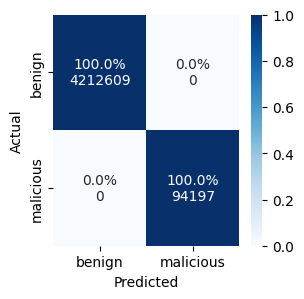

Training time for on all data: 43.5127

Evaluating model: random_forest


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,441.733109,5.957957,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75357}",3.445444e+06,"[[3370087, 0], [0, 75357]]",1.294237,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18840}",861362.000000,"[[842522, 0], [0, 18840]]"
1,452.885515,5.974013,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75358}",3.445445e+06,"[[3370087, 0], [0, 75358]]",1.239434,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
2,583.738924,9.542654,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75358}",3.445445e+06,"[[3370087, 0], [0, 75358]]",2.063871,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
3,587.045965,10.045556,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75358}",3.445445e+06,"[[3370087, 0], [0, 75358]]",1.235333,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
4,587.251212,6.914453,1.0,1.0,1.0,1.0,1.0,"{0: 3370088, 1: 75357}",3.445445e+06,"[[3370088, 0], [0, 75357]]",1.358907,1.0,1.0,1.0,1.0,1.0,"{0: 842521, 1: 18840}",861361.000000,"[[842521, 0], [0, 18840]]"
mean,530.530945,7.686926,1.0,1.0,1.0,1.0,1.0,NaN,3.445445e+06,NaN,1.438357,1.0,1.0,1.0,1.0,1.0,NaN,861361.200000,NaN
std,76.085632,1.970215,0.0,0.0,0.0,0.0,0.0,NaN,4.472136e-01,NaN,0.353249,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


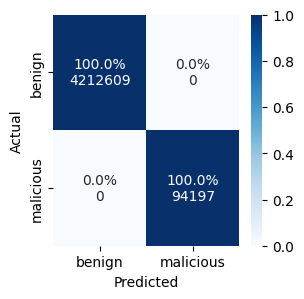

Training time for on all data: 544.1605

Evaluating model: neural_network


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,468.576933,49.310728,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75357}",3.445444e+06,"[[3370087, 0], [0, 75357]]",9.693847,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18840}",861362.000000,"[[842522, 0], [0, 18840]]"
1,442.189624,54.802157,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75358}",3.445445e+06,"[[3370087, 0], [0, 75358]]",12.954348,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
2,475.057205,52.323799,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75358}",3.445445e+06,"[[3370087, 0], [0, 75358]]",13.473621,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
3,485.837831,48.199284,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75358}",3.445445e+06,"[[3370087, 0], [0, 75358]]",11.749379,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
4,383.306028,29.118419,1.0,1.0,1.0,1.0,1.0,"{0: 3370088, 1: 75357}",3.445445e+06,"[[3370088, 0], [0, 75357]]",7.362017,1.0,1.0,1.0,1.0,1.0,"{0: 842521, 1: 18840}",861361.000000,"[[842521, 0], [0, 18840]]"
mean,450.993524,46.750877,1.0,1.0,1.0,1.0,1.0,NaN,3.445445e+06,NaN,11.046642,1.0,1.0,1.0,1.0,1.0,NaN,861361.200000,NaN
std,41.114075,10.191110,0.0,0.0,0.0,0.0,0.0,NaN,4.472136e-01,NaN,2.521405,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


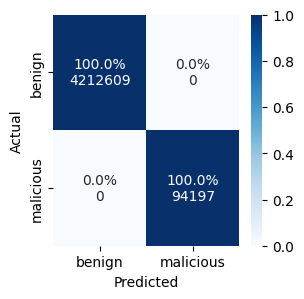

Training time for on all data: 474.9007

Evaluating model: support_vector_machine


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,59.548770,30.013782,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75357}",3.445444e+06,"[[3370087, 0], [0, 75357]]",7.333600,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18840}",861362.000000,"[[842522, 0], [0, 18840]]"
1,58.449388,30.635065,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75358}",3.445445e+06,"[[3370087, 0], [0, 75358]]",7.537816,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
2,58.547605,29.177264,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75358}",3.445445e+06,"[[3370087, 0], [0, 75358]]",7.077466,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
3,66.687670,28.807332,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75358}",3.445445e+06,"[[3370087, 0], [0, 75358]]",6.965558,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
4,51.917973,24.458615,1.0,1.0,1.0,1.0,1.0,"{0: 3370088, 1: 75357}",3.445445e+06,"[[3370088, 0], [0, 75357]]",5.969303,1.0,1.0,1.0,1.0,1.0,"{0: 842521, 1: 18840}",861361.000000,"[[842521, 0], [0, 18840]]"
mean,59.030281,28.618412,1.0,1.0,1.0,1.0,1.0,NaN,3.445445e+06,NaN,6.976748,1.0,1.0,1.0,1.0,1.0,NaN,861361.200000,NaN
std,5.245469,2.432379,0.0,0.0,0.0,0.0,0.0,NaN,4.472136e-01,NaN,0.605672,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


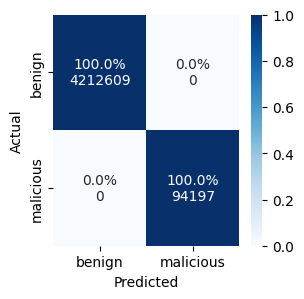

Training time for on all data: 83.6692

Evaluating model: hist_gradient_boosting


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,123.440236,9.863609,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75357}",3.445444e+06,"[[3370087, 0], [0, 75357]]",1.844976,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18840}",861362.000000,"[[842522, 0], [0, 18840]]"
1,113.571395,12.323522,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75358}",3.445445e+06,"[[3370087, 0], [0, 75358]]",3.076446,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
2,122.606815,11.716957,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75358}",3.445445e+06,"[[3370087, 0], [0, 75358]]",2.126170,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
3,108.514005,12.547814,1.0,1.0,1.0,1.0,1.0,"{0: 3370087, 1: 75358}",3.445445e+06,"[[3370087, 0], [0, 75358]]",3.094638,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
4,125.922510,8.641689,1.0,1.0,1.0,1.0,1.0,"{0: 3370088, 1: 75357}",3.445445e+06,"[[3370088, 0], [0, 75357]]",1.959615,1.0,1.0,1.0,1.0,1.0,"{0: 842521, 1: 18840}",861361.000000,"[[842521, 0], [0, 18840]]"
mean,118.810992,11.018718,1.0,1.0,1.0,1.0,1.0,NaN,3.445445e+06,NaN,2.420369,1.0,1.0,1.0,1.0,1.0,NaN,861361.200000,NaN
std,7.414398,1.696521,0.0,0.0,0.0,0.0,0.0,NaN,4.472136e-01,NaN,0.615427,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


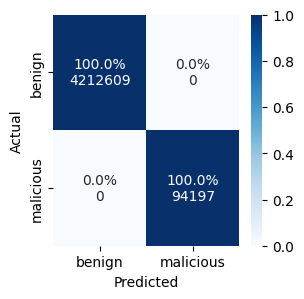

Training time for on all data: 61.5797



In [7]:
# Split the data in train and test
# Do Stratified K-fold cross validation (n=5), afterwards train model on all data and save to disk. 
s_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

models = {}

for model_name in available_models_base:
    print("Evaluating model: {}".format(model_name))

    # Cross evaluate the selected model
    ml_pipeline = get_model(model_name)
    results = cross_evaluate(ml_pipeline, X, y, s_kfold, metrics_func=evaluate_predictions, n_jobs=5)
    results.to_csv(f"{result_dir}/{model_name}_results.csv", index=True)
    results.to_pickle(f"{result_dir}/{model_name}_results.p")
    display(results)

    # Plot the aggregated confusion matrix over all test folds
    print("Aggregated test confusion matrix:")
    agg_conf_matrix = np.sum([np.array(matrix) for matrix in results['test_conf_matrix'].dropna()], axis=0)
    plt = plot_confusion_matrix(agg_conf_matrix, figsize=(3,3))
    plt.savefig(f"{result_dir}/{model_name}_conf_matrix.png", format='png', bbox_inches='tight')
    plt.savefig(f"{result_dir}/{model_name}_conf_matrix.eps", format='eps', bbox_inches='tight')
    plt.show()

    # Train the model on all data
    start_time = time.time()
    if model_name == 'one_rule':
        # Prevent information leakage by using the best rule from the cross evaluation
        models[model_name] = ml_pipeline.fit(X, y, clf__feature_idx=32)
    else:
        models[model_name] = ml_pipeline.fit(X, y)
    training_time = time.time() - start_time
    print("Training time for on all data: {:.4f}".format(training_time))

    # Save the model
    f = open(f"{result_dir}/{model_name}.p", "wb")
    pickle.dump(models[model_name], f)
    f.close()
    print()